In [2]:
from google.colab import drive
drive.mount("/content/drive")

!mkdir -p /content/data
!cp /content/drive/MyDrive/text-to-sound/data/* /content/data/
!ls -lh /content/data

CKPT = "/content/drive/MyDrive/text-to-sound/checkpoints/"

Mounted at /content/drive
total 1.2G
-rw------- 1 root root 1.3M Nov  5 20:17 captions_dev.csv
-rw------- 1 root root  25M Nov  5 20:17 clap_audio.npy
-rw------- 1 root root 125M Nov  5 20:17 clap_text.npy
-rw------- 1 root root 995M Nov  5 20:17 mels.npy
-rw------- 1 root root  136 Nov  5 20:17 mel_stats.npy
-rw------- 1 root root 952K Nov  5 20:17 meta.csv


In [3]:
import torch
import glob
import pandas as pd
import os
from IPython.display import Audio, display
import librosa, librosa.display
import matplotlib.pyplot as plt
import numpy as np
import random
!test -d BigVGAN || git clone -q https://github.com/NVIDIA/BigVGAN
!sed -i 's/proxies: Optional\[Dict\],/proxies: Optional[Dict] = None,/; s/resume_download: bool,/resume_download: bool = False,/' BigVGAN/bigvgan.py
!grep -n "proxies\|resume_download" BigVGAN/bigvgan.py
import sys; sys.path.insert(0, "BigVGAN")
import torch, bigvgan
from tqdm.auto import tqdm
from torch.utils.data import Dataset, DataLoader, Subset
import torch.nn.functional as F
import math
import torch.nn as nn
from transformers import ClapModel, ClapProcessor
%matplotlib inline
device = "cuda"
vocoder = bigvgan.BigVGAN.from_pretrained("nvidia/bigvgan_v2_22khz_80band_256x", use_cuda_kernel = False)
vocoder.remove_weight_norm()
vocoder = vocoder.eval().to(device)
print(vocoder.h.sampling_rate)

DATA = "/content/data/"
mels = np.load(DATA + "mels.npy", mmap_mode = "r")
stats = np.load(DATA + "mel_stats.npy")
MIN, MAX = stats[0], stats[1]
meta = pd.read_csv(DATA + "meta.csv")

422:        proxies: Optional[Dict] = None,
423:        resume_download: bool = False,
444:                proxies=proxies,
445:                resume_download=resume_download,
476:                proxies=proxies,
477:                resume_download=resume_download,
Loading weights from nvidia/bigvgan_v2_22khz_80band_256x
Removing weight norm...
22050


In [11]:
class MelDataset(Dataset):
    def __init__(self, split):
        self.rows = meta.index[meta["split"] == split].to_numpy()
        self.audio = np.load(DATA + "clap_audio.npy")
        self.mels = np.load(DATA + "mels.npy")

    def __len__(self):
        return len(self.rows)

    def __getitem__(self, i):
        row = self.rows[i]
        mel = torch.tensor(self.mels[row].astype("float32"))
        clap = torch.tensor(self.audio[row].astype("float32"))
        clap = F.normalize(clap, dim = 0)
        return mel, clap

train_data = MelDataset("train")
loader = DataLoader(train_data, batch_size = 32, shuffle = True, num_workers = 2)
tiny = Subset(train_data, range(16))
tiny_loader = DataLoader(tiny, batch_size = 16, shuffle = True)

In [5]:
mel, clap = next(iter(loader))
m = mel[0]
m = ((m + 1) / 2) * (MAX - MIN) + MIN
m = m.to(device)

with torch.inference_mode():
    wav = vocoder(m)
wav = wav.squeeze().cpu().numpy()
Audio(wav, rate = 22050)

In [12]:
class Autoencoder(nn.Module):
  def __init__(self):
    super().__init__()
    self.encoder = nn.Sequential(
      nn.Conv2d(1, 64, 3, 1, 1),
      nn.SiLU(),
      nn.Conv2d(64, 64, 3, 1, 1),
      nn.SiLU(),
      nn.Conv2d(64, 128, 3, 2, 1),
      nn.SiLU(),
      nn.Conv2d(128, 128, 3, 1, 1),
      nn.SiLU(),
      nn.Conv2d(128, 256, 3, 2, 1),
      nn.SiLU(),
      nn.Conv2d(256, 256, 3, 1, 1),
      nn.SiLU(),
      nn.Conv2d(256, 8, 3, 1, 1),
    )
    self.decoder = nn.Sequential(
        nn.Conv2d(4, 256, 3, 1, 1),
        nn.SiLU(),
        nn.Conv2d(256, 256, 3, 1, 1),
        nn.SiLU(),
        nn.Upsample(scale_factor = 2),
        nn.Conv2d(256, 128, 3, 1, 1),
        nn.SiLU(),
        nn.Conv2d(128, 128, 3, 1, 1),
        nn.SiLU(),
        nn.Upsample(scale_factor = 2),
        nn.Conv2d(128, 64, 3, 1, 1),
        nn.SiLU(),
        nn.Conv2d(64, 64, 3, 1, 1),
        nn.SiLU(),
        nn.Conv2d(64, 1, 3, 1, 1),
    )
  def forward(self, x):
    mu, logvar = self.encoder(x).chunk(2, dim = 1)
    z = mu + torch.exp(0.5 * logvar) * torch.randn_like(mu)
    return self.decoder(z), mu, logvar

In [ ]:
%%script false --no-raise-error

model = Autoencoder().to(device)
opt = torch.optim.Adam(model.parameters(), lr = 1e-3)
tiny = Subset(train_data, range(16))
tiny_loader = DataLoader(tiny, batch_size = 16, shuffle = True)

EPOCHS = 2000
for epoch in range(EPOCHS):
  for mel, clap in tiny_loader:
    x = mel.to(device)
    out, mu, logvar = model(x)
    recon = F.l1_loss(out, x)
    kl = -0.5 * torch.mean(1 + logvar - mu ** 2 - torch.exp(logvar))
    loss = recon + 1e-6 * kl
    opt.zero_grad()
    loss.backward()
    opt.step()
  if epoch % 100 == 0:
    print(epoch, loss.item())

print(mu.mean().item(), mu.std().item(), logvar.mean().item())
print(recon.item(), kl.item())

In [ ]:
model = Autoencoder().to(device)
opt = torch.optim.Adam(model.parameters(), lr = 2e-4)

EPOCHS = 20
for epoch in range(EPOCHS):
  total_recon, total_kl = 0, 0
  for mel, clap in tqdm(loader):
    x = mel.to(device)
    out, mu, logvar = model(x)
    recon = F.l1_loss(out, x)
    kl = -0.5 * torch.mean(1 + logvar - mu ** 2 - torch.exp(logvar))
    loss = recon + 1e-5 * kl
    opt.zero_grad()
    loss.backward()
    torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
    opt.step()
    total_recon += recon.item()
    total_kl += kl.item()
  print(epoch, total_recon / len(loader), total_kl / len(loader), mu.std().item())
  torch.save(model.state_dict(), CKPT + "vae_20ep.pt")

  0%|          | 0/714 [00:00<?, ?it/s]

0 0.060445514024973584 18.429569412050057 5.371230602264404


  0%|          | 0/714 [00:00<?, ?it/s]

1 0.03828824997073462 17.725978246256084 3.3593578338623047


  0%|          | 0/714 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7fe200a45bc0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7fe200a45bc0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

... (23 outputs left out)

  0%|          | 0/714 [00:00<?, ?it/s]

13 0.02392270022100594 6.742340179384589 1.3970742225646973


  0%|          | 0/714 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7fe200a45bc0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7fe200a45bc0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

0.026399243623018265


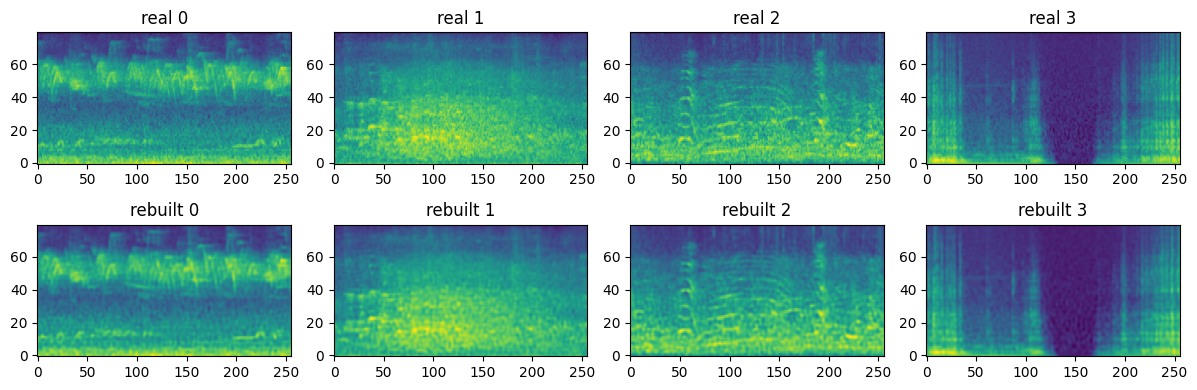

originals


reconstructions


In [8]:
val_data = MelDataset("val")
val_loader = DataLoader(Subset(val_data, [0, 500, 1000, 1500]), batch_size = 4)
real, _ = next(iter(val_loader))
real = real.to(device)
model.eval()
with torch.no_grad():
    mu, _ = model.encoder(real).chunk(2, dim = 1)
    rebuilt = model.decoder(mu).clamp(-1, 1)
print(F.l1_loss(rebuilt, real).item())

fig, axes = plt.subplots(2, 4, figsize = (12, 4))
for i in range(4):
    axes[0, i].imshow(real[i].squeeze().cpu().numpy(), origin = "lower", aspect = "auto")
    axes[0, i].set_title(f"real {i}")
    axes[1, i].imshow(rebuilt[i].squeeze().cpu().numpy(), origin = "lower", aspect = "auto")
    axes[1, i].set_title(f"rebuilt {i}")
plt.tight_layout()
plt.show()

m = ((real + 1) / 2) * (MAX - MIN) + MIN
print("originals")
with torch.inference_mode():
    wav = vocoder(m.squeeze(1))
for i in range(4):
    display(Audio(wav[i].squeeze().cpu().numpy(), rate = 22050))

m = ((rebuilt + 1) / 2) * (MAX - MIN) + MIN
print("reconstructions")
with torch.inference_mode():
    wav = vocoder(m.squeeze(1))
for i in range(4):
    display(Audio(wav[i].squeeze().cpu().numpy(), rate = 22050))